# OSM → 形态:权力如何改写城市天际线
### OSM → Form: how power rewrites the skyline

这是一份**动手做**的练习册。一条 lean、纯 Python、零 AI 的管线,你一格一格跑下去、改两张 YAML、看天际线怎么变。

**核心想法 / The core idea:**

> 拿真实 OSM 建筑(footprint + 高度)→ 用一张**可编辑的查表**把每栋对应到一个**利益相关者(stakeholder:政府 / 开发商 / 居民 / 在地非正式)**→ 切换不同的**权力情景(power scenario)**,情景**只调高度**(footprint 与标签不动)→ 看天际线长成不同的样子。

这是一个 **forward(正向)** 练习:**改权力 → 看形态**。我们*绝不*反过来从形状去猜「这是谁的楼」—— 那会骗人。

**你要做的事 / Your job**:跑代码格、改 YAML、重跑、对照天际线。每一格都有 `▶ 运行`、`✏️ 改`、`👀 看` 三种动作。

样本数据:`data/buildings.csv` — 新加坡 大巴窑(Toa Payoh)的 **1163 栋** OSM 建筑(osmnx 抓取)。


---
## ✏️ 你可以改什么(全篇只在这里讲一次)/ What you can change — explained ONCE

整条管线的「旋钮」只有**两张 YAML**,改它们不用碰任何 Python。后面每一步只会用一行小字提醒「这步可改哪张」,不再重复下面的细节。

| 文件 / File | 改它 = 改什么 | 怎么改 |
|---|---|---|
| **`stakeholder_lookup.yaml`** | **谁算谁的** —— 哪个 OSM tag 算 state / developer / resident / informal,加上 `order` 优先序(第一个命中即定) | 把某个 `building=` / `amenity=` 值移到别的 stakeholder 名下;或调 `order` 先后 |
| **`power_scenarios.yaml`** | **权力如何改写高度** —— 每个情景 = 各 stakeholder 一套高度政策:`mult`(权重/乘数)、`cap_m`(上限)、`_mode`:`conserve`(容积守恒,只重分配)/ `grow`(只增长) | 调某方 `mult`、加 `cap_m`、新增情景、或切 `_mode` |

**另外两个旋钮:**
- **跑哪个情景** —— Step 4 改 `SCEN_NAMES`。
- **(进阶)`FLOOR_H`** —— 楼层高(默认 3.5 m),换算 GFA 时用;改它会平移所有 GFA 估计。

### 🔒 故意固定、不准动 / Fixed on purpose
**footprint(真实 OSM 多边形)** 与 **stakeholder 标签** 全程不变 —— **只有高度会动**。

### 诚实的边界 / Honest limits(只在这里完整列一次)
- 高度多为**估计值**(`building:levels × 3.5`),少数实测 `height` tag —— 别把估计当测量。
- `unknown`(`building=yes` 或无可辨 tag)**不硬猜** —— 诚实保留未知。
- **单向 forward-only**:power → form,绝不从形状反推「谁的楼」。
- 「谁的权利」是一张**离散、可编辑的对应表**,不是真实产权考证 —— 教学练习,不是规划预测。

> **核心循环 / The loop:** 改一张 YAML → 回到对应代码格 → 重跑 → 看天际线变化。这就是「亲手做一个反事实 / authoring a counterfactual」。


---
## 准备 / Setup

**▶ 运行下面这格。** 它导入 `common.py`(整条管线的共用工具:路径、常量、`load_buildings()` / `assign_all()` / `scenario_heights()` 等),并把 matplotlib 切到 inline,让图直接显示在 notebook 里。

**👀 看**:打印出来的 `STAKEHOLDERS`、`FLOOR_H`、诚实说明 —— 确认环境就绪。

> 如果报错 `ModuleNotFoundError`:先在终端 `pip install -r requirements.txt`。


In [3]:
import numpy as np
import pandas as pd

import common  # 整条管线的共用契约 / the shared pipeline contract
# 注意:common.py 在 import 时设了 matplotlib 后端为 'Agg'(用于存 PNG)。
# 我们在 import 之后再切回 inline,让图直接显示在 notebook 里。
# NOTE: common.py sets the 'Agg' backend on import; we switch to inline AFTER importing it.
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import Image, display

print("matplotlib backend:", matplotlib.get_backend())
print("ROOT      :", common.ROOT.name)
print("OUT 目录  :", common.OUT)
print("FLOOR_H   :", common.FLOOR_H, "m  (楼层高 / storey height)")
print("STAKEHOLDERS:", common.STAKEHOLDERS)
print("诚实说明 / honest note:\n ", common.honest_note())

matplotlib backend: inline
ROOT      : osm_power_to_form_teaching
OUT 目录  : C:\Users\Lenovo\Desktop\DF26_ws18-master\osm_power_to_form_python\osm_power_to_form_teaching\out
FLOOR_H   : 3.5 m  (楼层高 / storey height)
STAKEHOLDERS: ['state', 'developer', 'resident', 'informal', 'unknown']
诚实说明 / honest note:
  OSM tag 稀疏(building=yes/無tag→unknown)· 高度多為 levels×3.5 估計 · 「誰的權利」為 tag 的離散可編輯對應、非產權考證 · 新加坡 大巴窯(Toa Payoh) 教學樣本


---
## Step 0(可选 / optional)— 卫星 + figure-ground

先看真实长这样,后面的离散读法才有对照。下面这格会**联网**抓研究范围的卫星影像(Esri),把 OSM footprint 依 stakeholder 着色,存三张图:纯卫星、纯 figure-ground、两层叠加。

**▶ 运行**(需网络 + `contextily` / `pyproj`;没装就先 `pip install contextily pyproj`,或跳过这步,Step 1 起不依赖它)。

**👀 看**:真实街区 vs 我们的离散着色;三张图能并排比较。

**✏️ 这步可改**:`BBOX` / `UTM` 换研究范围 —— 详见下一节〈换地方〉。

> 档名内含 bbox,所以换地方重跑会**生成新档、不覆写**上一个地点的图。


In [4]:
# 研究范围 bbox=(W,S,E,N) 与 UTM(预设 新加坡 大巴窑;换地方见下方〈换地方〉一节)
BBOX = (103.838, 1.327, 103.862, 1.348)
UTM  = 32648

# 真的跑:抓卫星 + figure-ground,存三张 bbox 命名的 PNG(换 BBOX 重跑不会覆写上一个地点)
#   1) satellite_<bbox>.png      纯卫星,无任何文字
#   2) figureground_<bbox>.png   纯 figure-ground,只有颜色图例
#   3) satellite_overlay_<bbox>.png  两层叠加,只有颜色图例
# 这步可选:卫星底图需要 contextily/pyproj + 网络;没装就友好跳过,不影响 Step 1–5。
try:
    import step0_satellite as s0   # 联网抓 Esri 卫星影像 + 叠 OSM footprint(需 contextily/pyproj)
    paths = s0.run(bbox=BBOX, utm=UTM)
    print("→ 档名内含 bbox slug:", common.bbox_slug(BBOX))
    for p in paths:                  # 把存下的三张 PNG 直接显示在 notebook 里
        print(" ", p.name); display(Image(str(p)))
except ImportError as e:
    print("▶ 卫星底图需要 contextily:`pip install contextily`(连带 pyproj)。")
    print("  没装就跳过这步,不影响 Step 1–5。/ Optional; skipping. (%s)" % e)
except Exception as e:
    # 多半是没网络抓不到 Esri 影像;Step 0 本来就可选,跳过即可
    print("▶ Step 0 卫星底图跳过(可能没网络或抓图失败,不影响 Step 1–5):", type(e).__name__, e)

▶ 卫星底图需要 contextily:`pip install contextily`(连带 pyproj)。
  没装就跳过这步,不影响 Step 1–5。/ Optional; skipping. (No module named 'contextily')


---
## 🌍 换地方 / Switch the study location

自带的是新加坡 **大巴窑(Toa Payoh)**。换城市要**同时改三样、且对应同一地点**:

1. **数据 `buildings.csv`** —— 重抓 OSM(见下面方式三的 osmnx 示例)。
2. **`BBOX`** —— 新区域经纬度矩形,顺序 **`(W 西, S 南, E 东, N 北)`**。
3. **`UTM`** —— 公尺投影带号(让面积/距离以米计)。

`BBOX` / `UTM` 就定义在上面 **Step 0** 那一格。**最省事的方法:用下面〈方式零〉的 `bbox_utm(lat, lon, radius_m)`,只给一个中心点就同时拿到 `BBOX` + `UTM`**,再回 Step 0 改掉那两行重跑即可(会写出按新 bbox 命名的图,不覆写旧地点)。


### 方式零 · 最简单:只给一个中心点 / The easy default — just one center point ⭐

**最省事的换地方方法,推荐先用这个。** 在任意地图(Google Maps / 高德)上,对你想研究的地点**右键「复制坐标」**,会得到一个中心点 `lat, lon`(注意:地图给的是 **lat 纬度在前**)。把它填进下面的 `bbox_utm(lat, lon)`,再选一个半径(中心到边的米数,如 `1200`),就**同时**拿到 `BBOX` 和 `UTM` —— 不用拖框、不用查 UTM 带号。

下一格跑完会把 `BBOX, UTM` 一次算好;把它喂给上面 **Step 0** 那格(或后面的 live 重抓)即可。其余三种方式(拖框 / 两角 / 地名)留作备选,见再下一节。


In [5]:
import math
def bbox_utm(lat, lon, radius_m=1000):
    """只输入中心点 (lat, lon) + 半径(米,中心到边),自动给 BBOX=(W,S,E,N) 和 UTM EPSG。"""
    dlat = radius_m / 111320.0
    dlon = radius_m / (111320.0 * math.cos(math.radians(lat)))
    bbox = (lon - dlon, lat - dlat, lon + dlon, lat + dlat)   # (W, S, E, N) 经纬度
    utm  = (32600 if lat >= 0 else 32700) + int((lon + 180) // 6) + 1  # 北 326xx / 南 327xx
    return bbox, utm

# 用法:在 Google/高德 地图右键“复制坐标”得到一个中心点的 lat,lon,填进来即可:
BBOX, UTM = bbox_utm(lat=22.5414, lon=114.0560, radius_m=1200)   # ← 深圳福田示例
print("BBOX =", tuple(round(v,6) for v in BBOX))
print("UTM  =", UTM)

# 想换地方:把上面 lat/lon/radius_m 改成你的中心点重跑,就得到新的 BBOX、UTM。
# 然后回上面 Step 0 那格,用 `BBOX, UTM = bbox_utm(...)` 覆盖它的 BBOX/UTM 即可
#(live 重抓楼时也用同一个 BBOX/UTM,见下一节方式三的 osmnx 示例)。

BBOX = (114.044329, 22.53062, 114.067671, 22.55218)
UTM  = 32650


### 其余三种拿 BBOX 的方式(备选)/ Three more ways to get the BBOX (alternatives)

上面〈方式零〉的 `bbox_utm(lat, lon)` 已经够用;下面三种是备选,适合你想手动框范围或用地名。

**方式一 · 在线拖框(最直观)** — 打开 **bboxfinder.com**(或 OSM → Export → 手动选区),拖出研究区,它给出 `minX, minY, maxX, maxY` = `(W, S, E, N)`,复制填进 `BBOX`。

**方式二 · 地图取两角** — Google Maps / 高德 右键 **西南角** 与 **东北角**「复制坐标」;它给 `lat, lon`,要**翻成 `lon, lat`**,组成 `BBOX = (西南 lon, 西南 lat, 东北 lon, 东北 lat)`。

**方式三 · 用地名自动(osmnx,免手填)** — 给一个地名,让 `osmnx` geocode 出边界,用 `total_bounds` 当 `BBOX`、`estimate_utm_crs()` 自动定 `UTM`(见下一格注释)。需要 `osmnx` + 网络。

**UTM 怎么定** — 由经度决定:带号 `= floor((lon+180)/6)+1`;北半球 `32600+带号`、南半球 `32700+带号`。例:上海 `lon≈121.5 → 51N → 32651`,新加坡 `→ 32648`。下一格的 `utm_epsg()` 可直接算(`bbox_utm()` 里用的是同一公式)。


In [6]:
# —— UTM 速查(纯公式,可直接跑)/ UTM EPSG from a lon/lat (runnable) ——
def utm_epsg(lon, lat):
    """返回该点的 UTM EPSG:北半球 326xx、南半球 327xx。/ UTM EPSG for a lon/lat."""
    zone = int((lon + 180) // 6) + 1
    return (32600 if lat >= 0 else 32700) + zone

print("Toa Payoh  ->", utm_epsg(103.85, 1.34))   # 32648
print("Shanghai   ->", utm_epsg(121.50, 31.20))  # 32651
print("Beijing    ->", utm_epsg(116.40, 39.90))  # 32650

# ========== 方式一 / 二:手动填(从 bboxfinder 或 地图两角拿到后)==========
# BBOX = (W, S, E, N)        # 例 / e.g. 大巴窑 (103.838, 1.327, 103.862, 1.348)
# UTM  = utm_epsg((BBOX[0] + BBOX[2]) / 2, (BBOX[1] + BBOX[3]) / 2)

# ========== 方式三:用地名自动(需 osmnx + 网络;换地方时取消注释)==========
# import osmnx as ox
# place = "曹杨新村, 上海, 中国"               # 换成你的地名 / your place name
# gdf   = ox.geocode_to_gdf(place)             # geocode 出该地边界
# W, S, E, N = map(float, gdf.total_bounds)    # 直接得 BBOX(lon/lat 度)
# BBOX  = (W, S, E, N)
# UTM   = gdf.estimate_utm_crs().to_epsg()     # 自动定 UTM 带号
# print("BBOX =", BBOX, "| UTM =", UTM)
# # 再用同一地名抓楼,并投到该 UTM:
# gdf_b = ox.features_from_place(place, {"building": True}).to_crs(UTM)

# ========== 校验:第一栋质心从 UTM 投回经纬度,应落在 BBOX 内 ==========
# import pyproj
# chk = pyproj.Transformer.from_crs(UTM, 4326, always_xy=True).transform(*list(df.geom.iloc[0].centroid.coords)[0])
# print("质心 lon/lat:", chk, "  应在 W-E", (BBOX[0], BBOX[2]), " S-N", (BBOX[1], BBOX[3]), "内")

Toa Payoh  -> 32648
Shanghai   -> 32651
Beijing    -> 32650


---
## Step 1 — 读 OSM footprint(还没贴权力)/ Read footprints, no power yet

**▶ 运行**:`load_buildings()` 读 1163 栋、解析真实 footprint 几何、看高度分布与 tag 覆盖。这步**全灰** —— 还没有 stakeholder,先看清原料。

**👀 看**:
- `height_source` 占比 —— 大多是 `levels_x3.5`(楼层估)或 `default`(无资料),只有少数 `measured`(高度多是估计,不是测量)。
- tag 覆盖 —— `amenity` / `office` / `shop` 非常稀疏,这正是后面用「离散查表」而非语意推断的原因。

> 别把 footprint(地面那块多边形)当成 building envelope(体量)—— 体量 = footprint × 高度,要等套上高度才有。


In [7]:
df = common.load_buildings()       # 只读 OSM 樓本身,尚未 assign_all / raw OSM, not assigned yet
n = len(df)
print("总栋数 / buildings        :", n)
print("总 footprint 面积 / area  : {:,.0f} m²  (平均 {:.0f} m²/栋)".format(df.area_m2.sum(), df.area_m2.sum()/n))
print("高度 / height             : 平均 %.1f m | 最矮 %.1f m | 最高 %.1f m"
      % (df.height_m.mean(), df.height_m.min(), df.height_m.max()))
print("\n-- height_source 占比(测量 vs 估计)/ measured vs estimated --")
print(df.height_source.value_counts().to_dict())
print("\n-- tag 覆盖(非空栋数,看有多稀疏)/ tag coverage --")
for key in ("building", "amenity", "office", "shop"):
    nonempty = (df[key].map(common._t) != "").sum()
    print("  %-9s 非空 %5d / %d  (%.1f%%)" % (key, nonempty, n, 100*nonempty/n))
df.head(3)[["building","amenity","office","shop","height_m","height_source","area_m2"]]

总栋数 / buildings        : 1163
总 footprint 面积 / area  : 1,230,787 m²  (平均 1058 m²/栋)
高度 / height             : 平均 24.3 m | 最矮 0.0 m | 最高 147.0 m

-- height_source 占比(测量 vs 估计)/ measured vs estimated --
{'levels_x3.5': 603, 'default': 456, 'measured': 104}

-- tag 覆盖(非空栋数,看有多稀疏)/ tag coverage --
  building  非空  1163 / 1163  (100.0%)
  amenity   非空   116 / 1163  (10.0%)
  office    非空     1 / 1163  (0.1%)
  shop      非空     6 / 1163  (0.5%)


,building,amenity,office,shop,height_m,height_source,area_m2
0,commercial,,,,14.0,levels_x3.5,2251.4
1,yes,,,,12.0,default,2148.4
2,school,,,,12.0,default,13592.4


**▶ 运行画图。** 左:真实 OSM footprint(全灰,还没贴权力)。右:高度直方图,蓝=实测、绿=楼层估、灰=默认。


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the foll

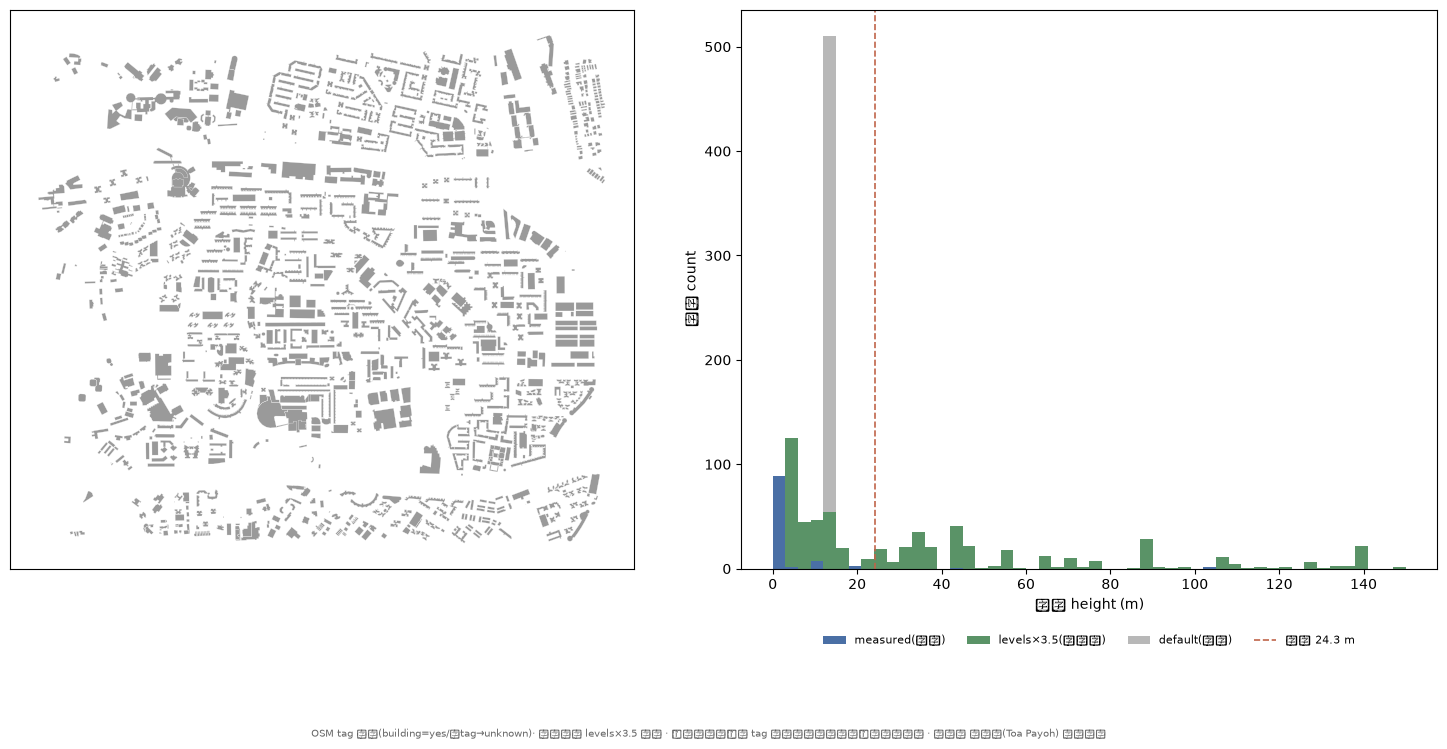

In [8]:
fig, (axL, axR) = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios":[1,1]})

# 左:真实 footprints,全灰(这步还没贴权力)/ left: real footprints, all grey
common.plot_footprints(axL, df, color_for=lambda r: "#9a9a9a")

# 右:高度直方图,依 height_source 叠色 / right: height histogram stacked by source
src_color = {"measured":"#4a6fa5", "levels_x3.5":"#5a9367", "default":"#b8b8b8"}
src_label = {"measured":"measured(实测)", "levels_x3.5":"levels×3.5(楼层估)", "default":"default(默认)"}
bins = range(0, int(df.height_m.max())+6, 3)
stacks = [df.loc[df.height_source==s, "height_m"] for s in src_color]
axR.hist(stacks, bins=bins, stacked=True, color=[src_color[s] for s in src_color],
         label=[src_label[s] for s in src_color])
axR.axvline(df.height_m.mean(), color="#c0654a", ls="--", lw=1.2, label="平均 %.1f m" % df.height_m.mean())
axR.set_xlabel("高度 height (m)"); axR.set_ylabel("栋数 count")
# 图例移到右图下方,不压数据 / legend below axes, off the data
axR.legend(loc="upper center", bbox_to_anchor=(0.5, -0.10), ncol=4, fontsize=8, frameon=False)
fig.text(0.5, -0.06, common.honest_note(), ha="center", fontsize=7, color="#666")
plt.tight_layout(); fig.subplots_adjust(bottom=0.18); plt.show()

---
## Step 2 — 利益相关者查表(贴标签)/ Stakeholder lookup

**▶ 运行**:`assign_all(df)` 用 `stakeholder_lookup.yaml` 给每栋加一列 `stakeholder` ∈ {state, developer, resident, informal, unknown}。纯 tag 查表、**第一个命中即定**(按 `order`)。**不动几何、不改高度**,只贴标签。

**👀 看**:各 stakeholder 的栋数与面积占比。`unknown` 很多 —— 那是 `building=yes` / 无可辨 tag 的楼,我们不硬猜(见开头诚实边界)。这不是 AI,就是一张可读查表。

**✏️ 这步可改**:`stakeholder_lookup.yaml`(谁算谁的;详见开头)—— 改完**重跑这一格**,权力地图就变。


In [9]:
lookup = common.load_lookup()
print("order(优先序,第一个命中即定):", lookup["order"])
print("default:", lookup.get("default"))
print("\nstate 收哪些 building tag:", lookup["rules"]["state"]["building"])
print("developer: any_shop =", lookup["rules"]["developer"].get("any_shop"),
      "| any_office =", lookup["rules"]["developer"].get("any_office"))

df = common.assign_all(df, lookup)   # 加 'stakeholder' 列;footprint/高度不变 / adds label only
counts = df["stakeholder"].value_counts()
areas  = df.groupby("stakeholder")["area_m2"].sum()
order  = common.STAKEHOLDERS
print("\n-- 棟数分布 / counts by stakeholder --")
for sh in order:
    print("  %-9s %-22s n=%4d  面积占比 %.1f%%"
          % (sh, common.SH_LABEL[sh], int(counts.get(sh,0)),
             100*float(areas.get(sh,0.0))/float(areas.sum())))

order(优先序,第一个命中即定): ['state', 'developer', 'resident', 'informal']
default: unknown

state 收哪些 building tag: ['government', 'civic', 'public', 'school', 'university', 'college', 'hospital', 'church', 'cathedral', 'chapel', 'temple', 'mosque', 'fire_station', 'train_station', 'transportation', 'stadium']
developer: any_shop = True | any_office = True

-- 棟数分布 / counts by stakeholder --
  state     政府/公共                  n= 102  面积占比 15.0%
  developer 開發商/資本                 n=  90  面积占比 17.6%
  resident  居民                     n= 521  面积占比 38.1%
  informal  在地/非正式                 n=  32  面积占比 5.8%
  unknown   未標(building=yes/無tag)  n= 418  面积占比 23.4%


**▶ 运行画图。** 左:真实 footprint 依 stakeholder 着色。右:栋数 / 面积占比长条。


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the foll

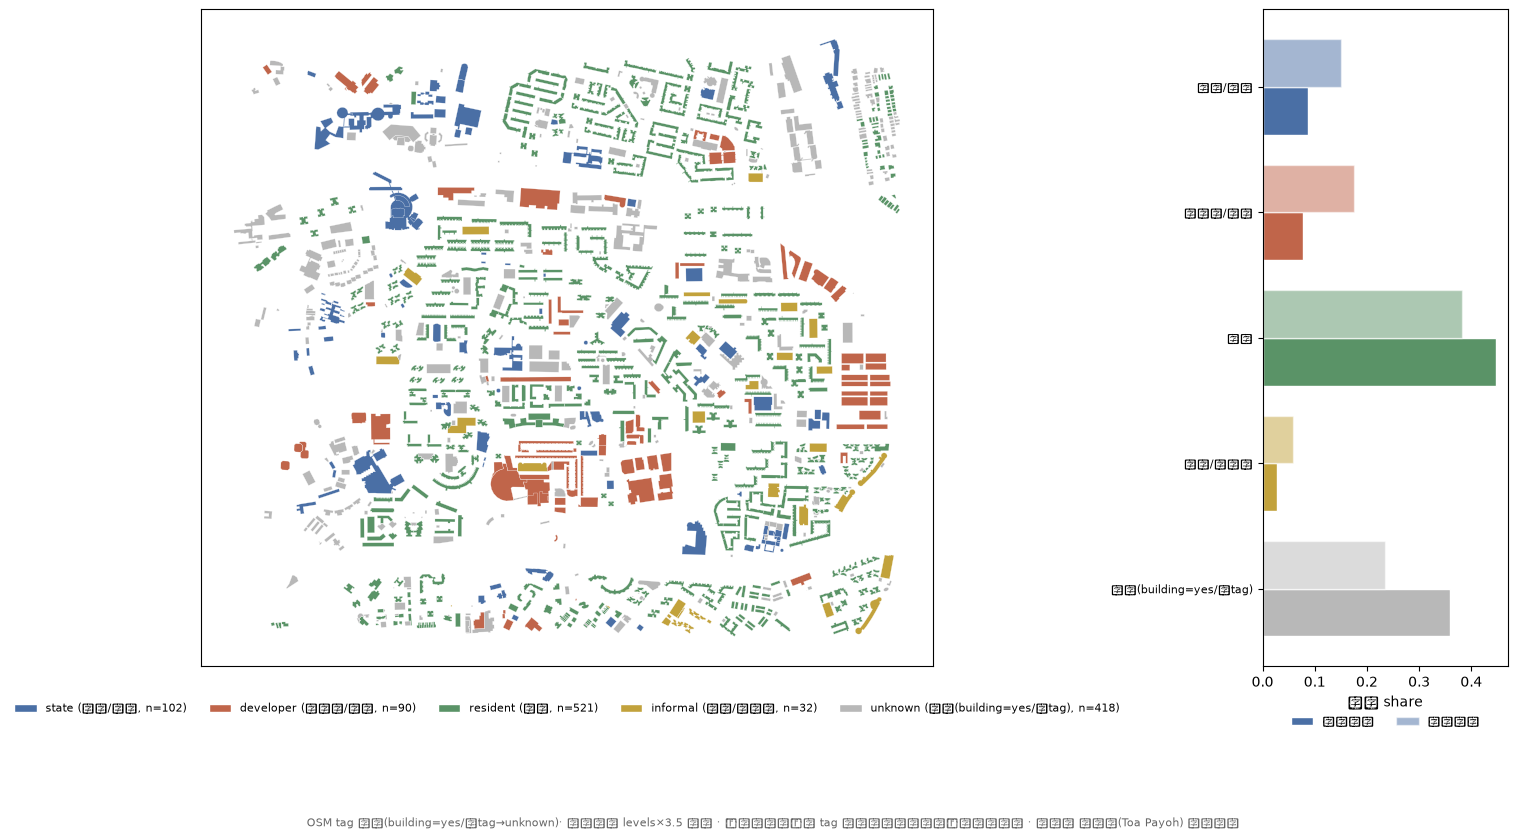

In [10]:
n_by = np.array([int(counts.get(sh,0)) for sh in order], float)
a_by = np.array([float(areas.get(sh,0.0)) for sh in order], float)
n_share = n_by / n_by.sum(); a_share = a_by / a_by.sum()

fig, (ax_map, ax_bar) = plt.subplots(1, 2, figsize=(15, 8), gridspec_kw={"width_ratios":[3,1]})
common.plot_footprints(ax_map, df, lambda r: common.SH_COLOR[r["stakeholder"]])
handles = [plt.Rectangle((0,0),1,1, facecolor=common.SH_COLOR[sh], edgecolor="white") for sh in order]
labels  = ["%s (%s, n=%d)" % (sh, common.SH_LABEL[sh], int(n_by[i])) for i, sh in enumerate(order)]
# stakeholder 图例放地图下方,不盖建筑 / map legend BELOW the axes, off the buildings
ax_map.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, -0.04),
              ncol=len(order), fontsize=8, frameon=False)

y = np.arange(len(order)); bw = 0.38; colors = [common.SH_COLOR[sh] for sh in order]
ax_bar.barh(y+bw/2, n_share, height=bw, color=colors, edgecolor="white", label="棟数占比")
ax_bar.barh(y-bw/2, a_share, height=bw, color=colors, edgecolor="white", alpha=0.5, label="面积占比")
ax_bar.set_yticks(y); ax_bar.set_yticklabels([common.SH_LABEL[sh] for sh in order], fontsize=8)
ax_bar.invert_yaxis(); ax_bar.set_xlabel("占比 share")
ax_bar.legend(loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=2, fontsize=8, frameon=False)
fig.text(0.5, -0.04, common.honest_note(), ha="center", fontsize=8, color="#666")
plt.tight_layout(); fig.subplots_adjust(bottom=0.16); plt.show()

---
## Step 3 — 权力情景(政策旋钮面板)/ Power scenarios

**▶ 运行**:把 `power_scenarios.yaml` 每个情景摊开。每个情景 = 各方一套高度政策:`mult`(乘数)、可选 `cap_m`(上限),加情景级 `_mode`:

- **`conserve`(容积守恒,重分配)**:总 GFA **不变**,`mult` 是「吸引力权重」会被正规化 —— 某方多拿、某方少拿,Σ新GFA = Σ旧GFA。`mult<1` 只是少分一点,**不会拆矮楼**。
- **`grow`(只增长)**:既有高度为地板,`mult ≥ 1` 在既有上加盖,总 GFA **上升**。铁律:**只增不减**(既有是早已协商沉淀的事实)。

**👀 看**:打印出来每个情景给每方的 `mult` / `cap`。

**✏️ 这步可改**:`power_scenarios.yaml`(权力如何改写高度;详见开头)—— 调 `mult` / 加 `cap_m` / 新增情景 / 切 `_mode`,**重跑这格与下面热图**。


In [11]:
scen = common.load_scenarios()
print("可用情景 / scenarios:", list(scen.keys()))
print()
for name, s in scen.items():
    mode = (s or {}).get("_mode", "conserve")
    print("[%s]  _mode=%s" % (name, mode))
    for sh in common.STAKEHOLDERS:
        pol = (s or {}).get(sh, {})
        if pol:
            extra = (" cap=%gm" % pol["cap_m"]) if "cap_m" in pol else ""
            print("    %-9s mult=%.2f%s" % (sh, float(pol.get("mult",1.0)), extra))
    if not (s or {}):
        print("    (空政策 = 基线,完全不变 / empty = baseline, unchanged)")

可用情景 / scenarios: ['current', 'developer_led', 'community_led', 'state_eco', 'developer_renewal']

[current]  _mode=conserve
[developer_led]  _mode=conserve
    state     mult=0.95
    developer mult=1.60
    resident  mult=0.90
    informal  mult=0.85
    unknown   mult=0.95
[community_led]  _mode=conserve
    state     mult=1.10
    developer mult=0.70
    resident  mult=1.30
    informal  mult=1.20
    unknown   mult=1.00
[state_eco]  _mode=conserve
    state     mult=1.60
    developer mult=0.70
    resident  mult=0.95
    informal  mult=1.00
    unknown   mult=0.95
[developer_renewal]  _mode=grow
    state     mult=1.00
    developer mult=1.50
    resident  mult=1.15
    informal  mult=1.00
    unknown   mult=1.20


**▶ 运行画图。** 乘数热图:红=拔高、蓝=压低(相对权重)、白=照旧、`cap`=上限。这是后面所有形态差异的**唯一来源**。


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the foll

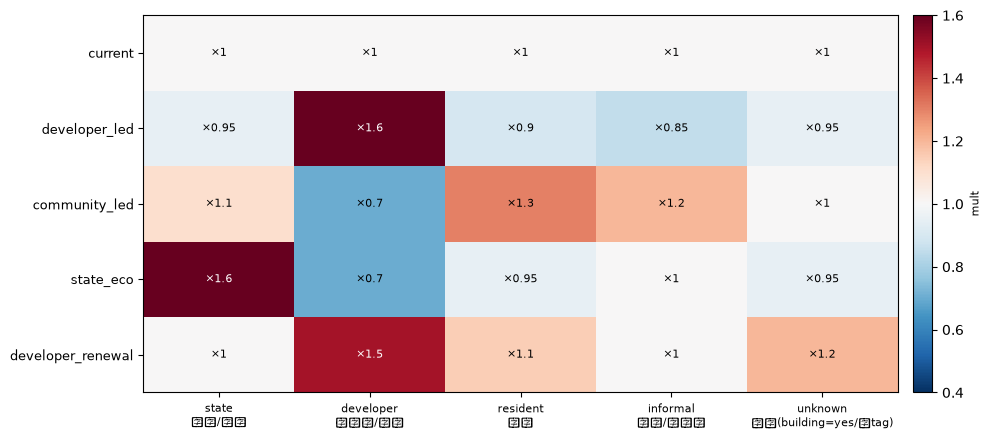

In [12]:
scen_names_all = list(scen.keys())
shs = common.STAKEHOLDERS
mult_mat = np.ones((len(scen_names_all), len(shs)))
for i, sn in enumerate(scen_names_all):
    for j, sh in enumerate(shs):
        mult_mat[i, j] = float((scen[sn] or {}).get(sh, {}).get("mult", 1.0))

fig, ax = plt.subplots(figsize=(10, 4.5))
vmax = max(float(np.abs(mult_mat-1.0).max()), 0.1)
im = ax.imshow(mult_mat, cmap="RdBu_r", vmin=1-vmax, vmax=1+vmax, aspect="auto")
ax.set_xticks(range(len(shs))); ax.set_xticklabels(["%s\n%s"%(s,common.SH_LABEL[s]) for s in shs], fontsize=8)
ax.set_yticks(range(len(scen_names_all))); ax.set_yticklabels(scen_names_all, fontsize=9)
for i in range(len(scen_names_all)):
    for j in range(len(shs)):
        pol = (scen[scen_names_all[i]] or {}).get(shs[j], {})
        txt = "×%.2g" % mult_mat[i,j]
        if "cap_m" in pol: txt += "\ncap%g" % pol["cap_m"]
        shade = abs(mult_mat[i,j]-1.0)/vmax
        ax.text(j, i, txt, ha="center", va="center", fontsize=8,
                color="white" if shade>0.55 else "black")
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02).set_label("mult", fontsize=8)
plt.tight_layout(); plt.show()

---
## Step 4 — 套用情景:只调高度 → 看新形态(回报 / payoff)

**▶ 运行**:同一批 1163 栋、同 footprint、同标签,分别套四个情景,`scenario_heights()` **只改高度**。引擎:
- `conserve`:`new_h_i = h_i × w_i × (ΣGFA / Σ(GFA·w))`,总 GFA 守恒,权力只重分配。
- `grow`:`h' = max(既有, min(h×mult, cap))`,既有为地板。

**👀 看**:conserve 四个情景「总 GFA ×base」几乎都 ×1.00 —— 别以为「没变」,**变的是分配不是总量**:看「各 stakeholder 平均高」哪方长高、哪方略矮。锁死 footprint、只放开高度,天际线差异就**完全归因于** YAML 那几个 `mult`/`cap`。

**✏️ 这步可改**:`SCEN_NAMES` 选对比情景;或改 `power_scenarios.yaml` 后**重跑这两格**。这就是核心循环。


In [13]:
# 选哪几个情景对比 / which scenarios to compare (可改 / editable)
SCEN_NAMES = ["current", "developer_led", "community_led", "state_eco"]
SCEN_TITLE = {"current":"current(基线)", "developer_led":"developer_led(开发商主导)",
              "community_led":"community_led(社区主导)", "state_eco":"state_eco(国家生态)"}

heights = {name: common.scenario_heights(df, scen[name]) for name in SCEN_NAMES}
base_gfa = float((df.area_m2 * heights["current"] / common.FLOOR_H).sum())

print("情景对照(只高度变;footprint 与标签不变)/ comparison (height only):")
print("  %-14s %10s %9s %8s" % ("scenario","GFA×base","mean_h","max_h"))
rows = []
for name in SCEN_NAMES:
    h = heights[name]
    gfa = float((df.area_m2 * h / common.FLOOR_H).sum())
    rows.append({"scenario":name, "gfa_x_base":gfa/base_gfa, "mean_h":float(h.mean()), "max_h":float(h.max())})
    print("  %-14s %9.2f× %8.1fm %7.0fm" % (name, gfa/base_gfa, h.mean(), h.max()))
metrics = pd.DataFrame(rows).set_index("scenario")

print("\n各 stakeholder 平均高 (m) × 情景 / mean height per stakeholder × scenario:")
print("  %-26s" % "stakeholder (n)" + "".join("%14s"%n for n in SCEN_NAMES))
by_sh = {}
for sh in common.STAKEHOLDERS:
    mask = (df["stakeholder"]==sh).values
    if not mask.any(): continue
    by_sh[sh] = {name: float(heights[name].values[mask].mean()) for name in SCEN_NAMES}
    label = "%s (%d)" % (common.SH_LABEL[sh], int(mask.sum()))
    print("  %-26s"%label + "".join("%13.1fm"%by_sh[sh][name] for name in SCEN_NAMES))

情景对照(只高度变;footprint 与标签不变)/ comparison (height only):
  scenario         GFA×base    mean_h    max_h
  current             1.00×     24.5m     147m
  developer_led       1.00×     23.7m     136m
  community_led       1.00×     25.1m     162m
  state_eco           1.00×     24.2m     143m

各 stakeholder 平均高 (m) × 情景 / mean height per stakeholder × scenario:
  stakeholder (n)                  current developer_led community_led     state_eco
  政府/公共 (102)                        10.6m         10.3m          9.8m         17.3m
  開發商/資本 (90)                        14.2m         23.1m          8.6m         10.3m
  居民 (521)                           39.4m         36.3m         43.3m         38.3m
  在地/非正式 (32)                        13.8m         12.0m         14.0m         14.1m
  未標(building=yes/無tag) (418)         12.5m         12.1m         10.6m         12.2m


**▶ 运行画图。** 4 连幅 footprint,按新高度用**同一色阶**着色(低=深紫、高=黄),可横向比对天际线。同一批楼,差异**纯粹来自「谁更有权」**。


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the foll

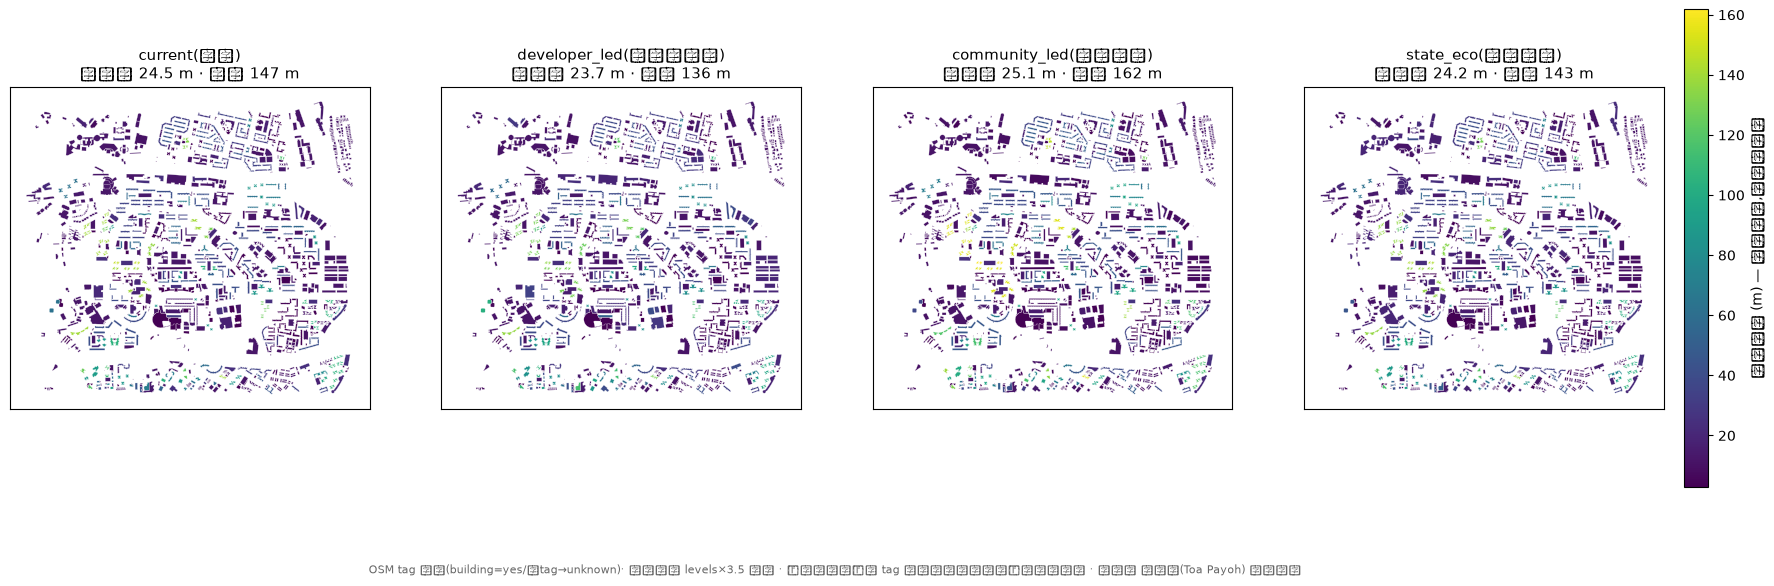

In [14]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
HEIGHT_CMAP = plt.get_cmap("viridis")
all_h = np.concatenate([h.values for h in heights.values()])
norm = Normalize(vmin=float(all_h.min()), vmax=float(all_h.max()))

fig, axes = plt.subplots(1, 4, figsize=(22, 6.2))
for ax, name in zip(axes, SCEN_NAMES):
    h = heights[name]; hmap = dict(zip(df.index, h.values))
    common.plot_footprints(ax, df, color_for=lambda r: HEIGHT_CMAP(norm(hmap[r.name])))
    # 面板标签(区分四幅,非图名)/ panel tag, not a figure title
    ax.set_title("%s\n平均高 %.1f m · 最高 %.0f m" % (SCEN_TITLE[name], h.mean(), h.max()), fontsize=11)
sm = ScalarMappable(norm=norm, cmap=HEIGHT_CMAP); sm.set_array([])
fig.colorbar(sm, ax=axes, fraction=0.018, pad=0.012).set_label("建物高度 (m) — 同一色阶,可横向比对", fontsize=10)
fig.text(0.5, -0.03, common.honest_note(), ha="center", fontsize=8, color="#666")
plt.show()

**▶ 运行画图。** 四面板:总 GFA ×base、平均高、最高、各 stakeholder 平均高。

**👀 看**:左上 conserve 下总 GFA 守恒(≈×1.00),真正的此消彼长全在右下「各 stakeholder 平均高」—— 政策打在谁身上。


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the foll

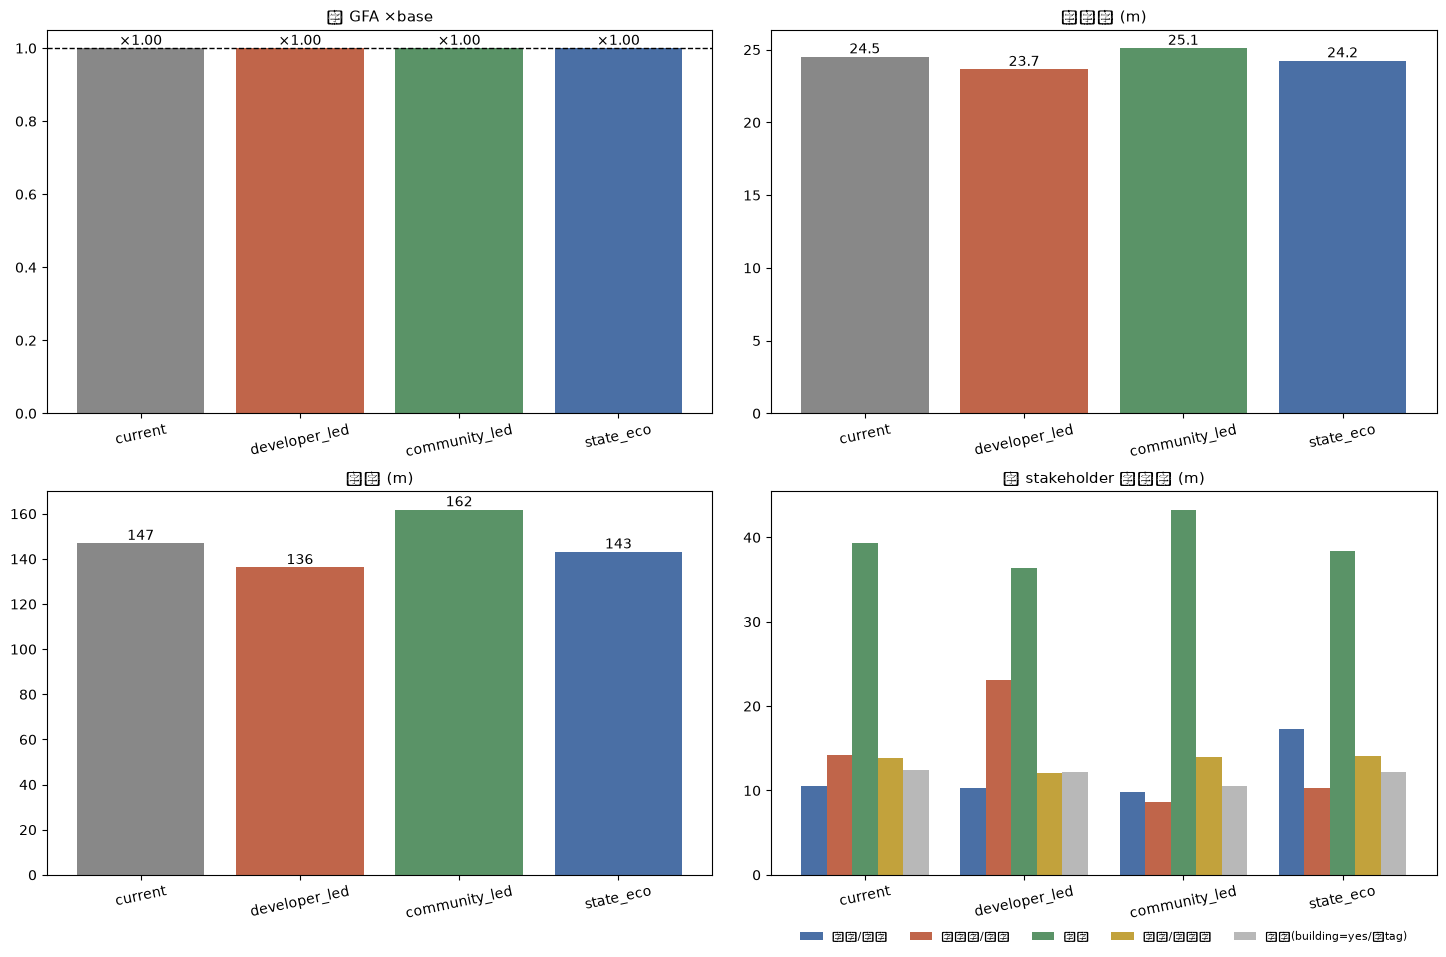

In [15]:
fig2, axs = plt.subplots(2, 2, figsize=(15, 10))
x = np.arange(len(SCEN_NAMES))
scen_colors = ["#888888", "#c0654a", "#5a9367", "#4a6fa5"]

axs[0,0].bar(x, metrics["gfa_x_base"], color=scen_colors); axs[0,0].axhline(1.0, ls="--", lw=1, color="k")
axs[0,0].set_title("总 GFA ×base", fontsize=11)   # 面板标签 / panel tag
for i,v in enumerate(metrics["gfa_x_base"]): axs[0,0].text(i, v, "×%.2f"%v, ha="center", va="bottom", fontsize=10)
axs[0,0].set_xticks(x); axs[0,0].set_xticklabels(SCEN_NAMES, rotation=12)

axs[0,1].bar(x, metrics["mean_h"], color=scen_colors); axs[0,1].set_title("平均高 (m)", fontsize=11)
for i,v in enumerate(metrics["mean_h"]): axs[0,1].text(i, v, "%.1f"%v, ha="center", va="bottom", fontsize=10)
axs[0,1].set_xticks(x); axs[0,1].set_xticklabels(SCEN_NAMES, rotation=12)

axs[1,0].bar(x, metrics["max_h"], color=scen_colors); axs[1,0].set_title("最高 (m)", fontsize=11)
for i,v in enumerate(metrics["max_h"]): axs[1,0].text(i, v, "%.0f"%v, ha="center", va="bottom", fontsize=10)
axs[1,0].set_xticks(x); axs[1,0].set_xticklabels(SCEN_NAMES, rotation=12)

n_sh = len(by_sh); w = 0.8/max(n_sh,1)
for k,(sh,d) in enumerate(by_sh.items()):
    vals = [d[name] for name in SCEN_NAMES]
    axs[1,1].bar(x + (k-(n_sh-1)/2)*w, vals, width=w, color=common.SH_COLOR[sh], label=common.SH_LABEL[sh])
axs[1,1].set_title("各 stakeholder 平均高 (m)", fontsize=11)
axs[1,1].set_xticks(x); axs[1,1].set_xticklabels(SCEN_NAMES, rotation=12)
# 图例放该面板下方,不压长条 / legend below this panel, off the bars
axs[1,1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=len(by_sh), fontsize=8, frameon=False)
fig2.tight_layout(); fig2.subplots_adjust(bottom=0.12); plt.show()

### grow 模式对照 / a `grow`-mode comparison

**▶ 运行**:`developer_renewal` 用 `_mode: grow`(都更新增,只增不减)。

**👀 看**:总 GFA **真的上升**(×1.16),和上面 conserve 的 ×1.00 对照,体会两种模式的本质差别。


In [16]:
h_grow = common.scenario_heights(df, scen["developer_renewal"])
gfa_grow = float((df.area_m2 * h_grow / common.FLOOR_H).sum())
print("developer_renewal (_mode=grow):")
print("  总 GFA ×baseline = ×%.2f   (对照 conserve 情景 ≈ ×1.00)" % (gfa_grow/base_gfa))
print("  平均高 %.1f m  →  current 平均高 %.1f m" % (h_grow.mean(), heights["current"].mean()))
print("  铁律:只增不减,既有高度是地板 / never below existing height")

developer_renewal (_mode=grow):
  总 GFA ×baseline = ×1.16   (对照 conserve 情景 ≈ ×1.00)
  平均高 28.3 m  →  current 平均高 24.5 m
  铁律:只增不减,既有高度是地板 / never below existing height


---
## Step 5 — 导出 3D 量体(OBJ + GH CSV)/ Export 3D massing

**▶ 运行**:`extrude_obj()` 把真实 footprint 挤成 3D 量体(墙 + 三角顶盖),导出 `current` 与一个情景的 `.obj`,再写 Rhino/Grasshopper 用的逐栋 CSV(centroid + area + 两种高度 + stakeholder)到 `out/`。

**👀 看**:两个 OBJ 叠起来,直接看出「谁被准许长高 / 压低」。导出**不改 footprint** —— 挤体用的就是原始 OSM 多边形,变的只有高度列。

> OBJ 坐标是 UTM 公尺,平移到 bbox 左下角附近;Rhino 单位是米。完整全部楼可在终端跑 `python3 step5_export_rhino.py [scenario] [--all-scenarios]`。


In [17]:
# 用真实 footprint 挤成量体(这里取前 80 栋示范,完整版可去掉 .head)
sub = df.head(80)
obj_cur, nv, nf = common.extrude_obj(sub, height_col="height_m")
print("city_current.obj  (前 80 栋示范): verts %d  faces %d" % (nv, nf))

# 写一个情景的 OBJ + GH CSV 到 out/
scen_name = "developer_led"
h2 = common.scenario_heights(df, scen[scen_name])
sub2 = sub.copy(); sub2["height_%s"%scen_name] = h2.loc[sub.index].values
obj_scen, nv2, nf2 = common.extrude_obj(sub2, height_col="height_%s"%scen_name)

(common.OUT / "city_current_demo.obj").write_text(obj_cur, encoding="utf-8")
(common.OUT / ("city_%s_demo.obj"%scen_name)).write_text(obj_scen, encoding="utf-8")
print("→ 写出 out/city_current_demo.obj 与 out/city_%s_demo.obj" % scen_name)

# GH/Rhino 逐栋表(全 1163 栋)/ per-building table for GH
import csv as _csv
gh_path = common.OUT / "buildings_export_demo.csv"
hall = common.scenario_heights(df, scen[scen_name])
with open(gh_path, "w", newline="", encoding="utf-8") as f:
    wr = _csv.writer(f)
    wr.writerow(["centroid_x","centroid_y","area_m2","height_m","height_%s"%scen_name,"stakeholder"])
    for (_, r), hh in zip(df.iterrows(), hall):
        c = r["geom"].centroid
        wr.writerow(["%.3f"%c.x, "%.3f"%c.y, "%.3f"%float(r.area_m2),
                     "%.3f"%float(r.height_m), "%.3f"%float(hh), r["stakeholder"]])
print("→ 写出 %s  (%d 行)" % (gh_path.name, len(df)))
print("\nRhino: File>Import out/city_*.obj   |   GH: 读 buildings_export_demo.csv")
print("提示 / note: 终端 `python3 step5_export_rhino.py [scenario] [--all-scenarios]` 可导出完整全部楼。")

city_current.obj  (前 80 栋示范): verts 13860  faces 7964
→ 写出 out/city_current_demo.obj 与 out/city_developer_led_demo.obj
→ 写出 buildings_export_demo.csv  (1163 行)

Rhino: File>Import out/city_*.obj   |   GH: 读 buildings_export_demo.csv
提示 / note: 终端 `python3 step5_export_rhino.py [scenario] [--all-scenarios]` 可导出完整全部楼。


**▶ 运行画图。** matplotlib 把前 80 栋的量体画成 3D(依 stakeholder 着色),只为感受;正式量体请去 Rhino/GH 看 OBJ。


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the foll

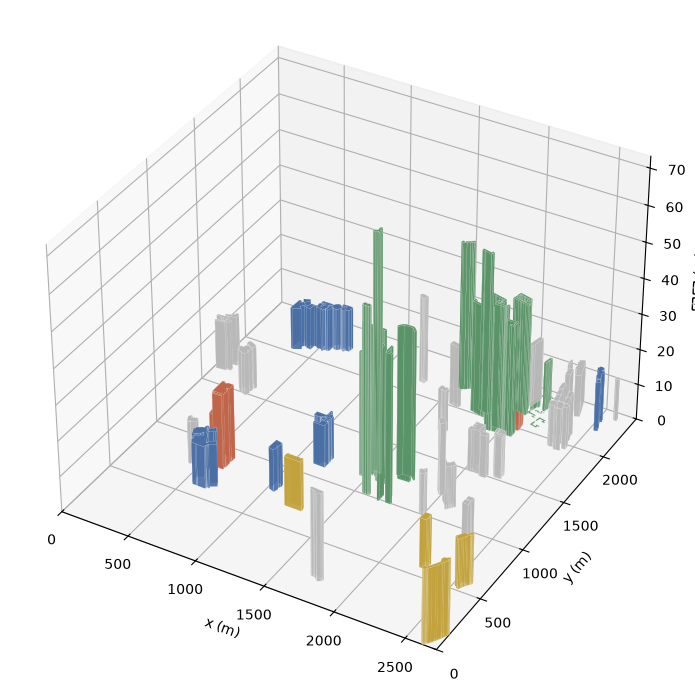

In [18]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from shapely.geometry import Polygon as _P

def building_walls(geom, h, ox, oy):
    polys = common._polys(geom); faces = []
    for poly in polys:
        ring = list(poly.exterior.coords)
        if len(ring) > 1 and ring[0]==ring[-1]: ring = ring[:-1]
        for i in range(len(ring)):
            j = (i+1) % len(ring)
            x0,y0 = ring[i]; x1,y1 = ring[j]
            faces.append([(x0-ox,y0-oy,0),(x1-ox,y1-oy,0),(x1-ox,y1-oy,h),(x0-ox,y0-oy,h)])
        faces.append([(x-ox,y-oy,h) for (x,y) in ring])  # 顶盖近似 / roof approx
    return faces

ox = min(p.bounds[0] for g in sub["geom"] for p in common._polys(g))
oy = min(p.bounds[1] for g in sub["geom"] for p in common._polys(g))
fig = plt.figure(figsize=(11,7)); ax = fig.add_subplot(111, projection="3d")
for _, r in sub.iterrows():
    fcs = building_walls(r["geom"], float(r["height_m"]), ox, oy)
    col = common.SH_COLOR[r["stakeholder"]]
    ax.add_collection3d(Poly3DCollection(fcs, facecolor=col, edgecolor="white", linewidths=0.1, alpha=0.92))
xs = [p.bounds for g in sub["geom"] for p in common._polys(g)]
ax.set_xlim(0, max(b[2] for b in xs)-ox); ax.set_ylim(0, max(b[3] for b in xs)-oy)
ax.set_zlim(0, float(sub["height_m"].max())*1.1)
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)"); ax.set_zlabel("高度 (m)")
ax.view_init(elev=35, azim=-60); plt.tight_layout(); plt.show()

---
## 收尾:亲手做一个反事实 / Wrap-up: author your own counterfactual

你已经走完整条管线。现在动手做属于你的反事实 —— **改 YAML → 回到对应代码格 → 重跑 → 看天际线变化**:

1. **改「谁算谁的」** — 编辑 `stakeholder_lookup.yaml`(例:把 `building=hotel` 从 developer 移到 state),回 **Step 2** 重跑 → 权力地图变。
2. **改「权力如何改写高度」** — 编辑 `power_scenarios.yaml`(例:新增情景,把 `resident` 的 `mult` 调到 1.5、给 developer 加 `cap_m: 40`),回 **Step 3 / Step 4** 重跑 → 天际线变。
3. **比对** — 看 Step 4 的「各 stakeholder 平均高」长条:你的政策打在谁身上?

> 别忘了开头的诚实边界:只有**高度**会动,footprint 与标签固定;高度是估计,`unknown` 不硬猜,方向单向(power → form)。
>
> 一句话:**改 YAML 数字 = 问城市一个「如果……会怎样」,管线诚实地只用高度回答你。**


In [19]:
print("管线走完 / pipeline complete.")
print("两张可编辑 YAML / two editable YAMLs:")
print("  1) stakeholder_lookup.yaml  — 谁算谁的 / who counts as whom")
print("  2) power_scenarios.yaml     — 权力如何改写高度 / how power rewrites height")
print("\n固定的 / fixed: footprint + stakeholder 标签;只有高度会动 / only height moves.")
print(common.honest_note())

管线走完 / pipeline complete.
两张可编辑 YAML / two editable YAMLs:
  1) stakeholder_lookup.yaml  — 谁算谁的 / who counts as whom
  2) power_scenarios.yaml     — 权力如何改写高度 / how power rewrites height

固定的 / fixed: footprint + stakeholder 标签;只有高度会动 / only height moves.
OSM tag 稀疏(building=yes/無tag→unknown)· 高度多為 levels×3.5 估計 · 「誰的權利」為 tag 的離散可編輯對應、非產權考證 · 新加坡 大巴窯(Toa Payoh) 教學樣本
